# Schematic for methods of  perturbations 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature


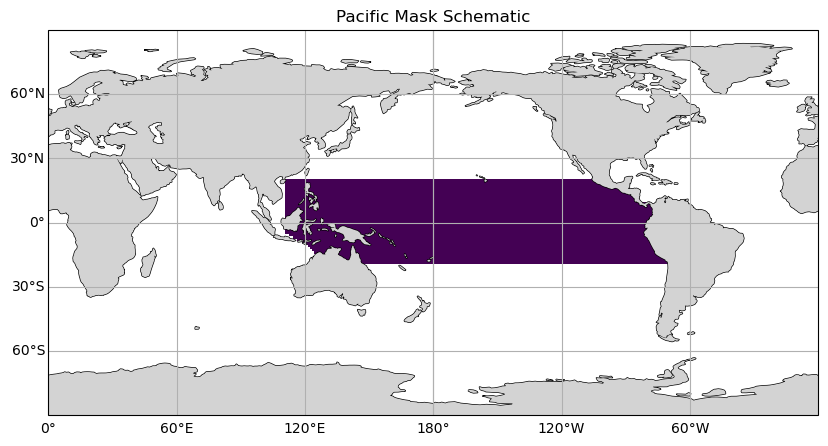

In [ ]:

sst = noaa_sst.isel(time =0)

def pacific_mask(sst):

    LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130]
    LatsPts_pos = [-20,-10,-5,10,20,20,15,15,10,5,-20,-20]

    polygon = np.array(list(zip(LonsPts_pos, LatsPts_pos)))

    xv, yv = sst.lon, sst.lat
    lon2d, lat2d = np.meshgrid(xv, yv)

    points = np.hstack((
        lon2d.reshape((-1,1)),
        lat2d.reshape((-1,1))
    ))

    path = mpath.Path(polygon)

    mask = path.contains_points(points)
    mask.shape = lon2d.shape

    mask = mask.astype(float)
    mask[mask == 0] = np.nan

    return mask


# example global grid
lon = np.arange(0, 360, 1)
lat = np.arange(-90, 91, 1)

class Dummy:
    pass

sst = Dummy()
sst.lon = lon
sst.lat = lat

mask = pacific_mask(sst)

# plotting
proj = ccrs.PlateCarree(central_longitude=180)

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=proj)

ax.set_global()

im = ax.pcolormesh(
    lon,
    lat,
    mask,
    transform=ccrs.PlateCarree(),
)

ax.coastlines()
ax.add_feature(cfeature.LAND, zorder=2, facecolor='lightgrey')

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

plt.title("Pacific Mask Schematic")

plt.show()

NameError: name 'os' is not defined

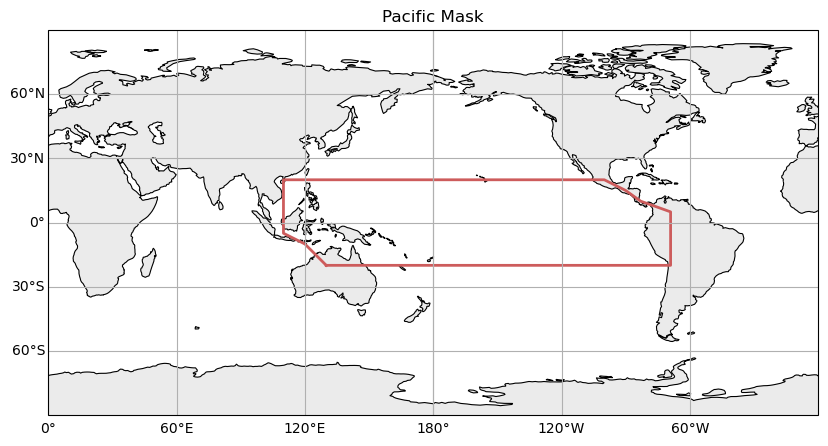

In [2]:

# Pacific mask polygon
LonsPts_pos = [130,120,110,110,110,260,270,270,277,291,291,130]
LatsPts_pos = [-20,-10,-5,10,20,20,15,15,10,5,-20,-20]

# plotting
proj = ccrs.PlateCarree(central_longitude=180)

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=proj)

ax.set_global()

# draw polygon outline
ax.plot(
    LonsPts_pos,
    LatsPts_pos,
    color='indianred',
    linewidth=2,
    transform=ccrs.PlateCarree()
)

ax.coastlines(linewidth=0.8)

# paler continents
ax.add_feature(
    cfeature.LAND,
    facecolor='0.92',
    edgecolor='none'
)

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

plt.title("Pacific Mask")


plt.savefig(
    os.path.expanduser("~/Desktop/pacific_mask_schematic.pdf"),
    bbox_inches="tight"
)

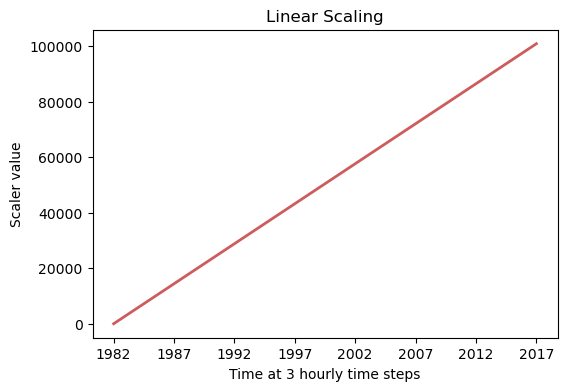

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# start/end values
start_year = 1982
end_year = 2017

x = [start_year, end_year]
y = [0, 100800]

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(x, y, linewidth=2, color = 'indianred')

# evenly spaced ticks
ticks = np.linspace(start_year, end_year, 8)

ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t)}" for t in ticks])

# angle labels
# plt.setp(ax.get_xticklabels(), rotation=45, ha='right')


ax.set_xlabel("Time at 3 hourly time steps")
ax.set_ylabel("Scaler value")

ax.set_title("Linear Scaling")



plt.savefig(
    os.path.expanduser("~/Desktop/scaler_schematic.pdf"),
    bbox_inches="tight"
)